# MTRNet: Cascade Out-of-Distribution Rejection for Rice Leaf Disease Diagnosis

Reproduction of the **Cascade Inference System (CIS)** evaluation in:
*"Knowledge-guided multi-task learning with cascade out-of-distribution rejection for rice leaf disease diagnosis"*
(PLOS ONE 21(11): e0362080, 2026, DOI [10.1371/journal.pone.0362080](https://doi.org/10.1371/journal.pone.0362080)).
Code: [github.com/lvxiangfly/MTRNet](https://github.com/lvxiangfly/MTRNet) @ commit `803ec0ef19c340f52490f505838d27ae17889d47`.
Data + released checkpoint: [Figshare 33065840](https://doi.org/10.6084/m9.figshare.33065840) (CC BY 4.0).

**Executed scope (partial demonstration):** load the authors' released checkpoint `models/multitask_best_model.pth`
and run the authors' own evaluation path (`code/run_frr.py` → `code/cascade_inference.py`):

- **FRR** (False Rejection Rate) on the 595-image rice-disease **test** split,
- **ORR** (OOD Rejection Rate) on the **1,000 environmental-noise (cat/dog) images**,
- Stage I (Bio-Grey Filter) / Stage II (Visual Consistency Check) attribution.

**Not in scope:** training, 5-seed statistics, source-aware 5-fold cross-validation, the loss-weight sweep, and Grad-CAM.
A single-checkpoint ORR/FRR run is **not** a verification of the paper's dataset-level statistics.

The notebook calls the authors' pinned Python modules directly (no AI re-implementation of the scientific
core); the only AI-written glue is the download/extraction/display code, marked below.

**実行内容（部分的な再現）:** 著者公開の学習済みチェックポイントを用い、著者自身の評価コード
(`code/run_frr.py` / `code/cascade_inference.py`) で、595 枚の稲病害テスト画像に対する FRR（誤拒否率）と
1,000 枚の OOD（環境ノイズ）画像に対する ORR（OOD 拒否率）、および Stage I / Stage II の内訳を再現します。
学習・多シード統計・source-aware 交差検証・Grad-CAM は対象外です。

## Runtime selection / ランタイム選択

This notebook runs on a **free CPU runtime** (recommended: `ランタイム` → `ランタイムのタイプを変更` → `CPU`)
or on a **T4 GPU**; it detects the device itself and uses the same checkpoint, preprocessing, and metrics on either.
Expected: ~336 MB download (Figshare zip), ~10–20 min end-to-end on CPU (ResNet-50 inference over 1,595 images
at the paper's measured 77–172 ms/image CPU latency), faster on T4.
Use `ランタイム` → `すべてのセルを実行` (Run all) from top to bottom.

**このノートブックは CPU でも T4 GPU でも動作します（推奨は無料の CPU）。** 約 336 MB のダウンロードと
10〜20 分程度の実行時間を見込んでください。

### 1. Environment check / 環境の確認

Prints the runtime's Python and library versions and selects the device. All required packages
(torch, torchvision, OpenCV, NumPy, Pillow) are preinstalled on standard Colab runtimes;
the cell fails loudly rather than silently substituting anything if one is missing.
**出力:** バージョン情報と、選択されたデバイス（CPU または GPU）。

In [ ]:
import sys
import torch, torchvision, cv2, numpy as np, PIL

print("Python:", sys.version.split()[0])
for m in (torch, torchvision, cv2, np, PIL):
    print(f"{m.__name__:12s} {getattr(m, '__version__', '?')}")
assert torch.__version__ >= "2.0" and torchvision.__version__ >= "0.15"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Runtime: CPU (scientifically faithful for this inference-only demo)")

Python: 3.13.18
torch        2.14.1+cpu
torchvision  0.29.1+cpu
cv2          5.0.0
numpy        2.4.6
PIL          11.3.0
Runtime: CPU (scientifically faithful for this inference-only demo)


### 2. Fetch the authors' pinned evaluation code / 著者コードの取得（コミット固定）

Downloads the four author modules needed by the CIS evaluation from the pinned GitHub commit
and verifies each file against its **Git blob SHA-1** before use:

| file | role |
|---|---|
| `expert_matrix.py` | Expert Knowledge Matrix (paper Table 1) |
| `mtrnet_model.py` | ResNet-50 + 4 heads (diagnosis/shape/color/location) |
| `dataset.py` | eval transforms (Resize 224 + ImageNet normalization) |
| `cascade_inference.py` | Stage I Bio-Grey Filter + Stage II VCC, `evaluate_ORR`/`evaluate_FRR` |

**出力:** 各ファイルのバイト数と blob ハッシュ検証結果（不一致ならエラーで停止）。

In [ ]:
import hashlib, pathlib, sys, urllib.request

COMMIT = "803ec0ef19c340f52490f505838d27ae17889d47"
RAW_BASE = f"https://raw.githubusercontent.com/lvxiangfly/MTRNet/{COMMIT}"
AUTHOR_CODE = pathlib.Path("/content/mtrnet_author_code")
AUTHOR_CODE.mkdir(parents=True, exist_ok=True)

PINNED_FILES = {  # name -> (size in bytes, git blob sha1) at commit 803ec0e
    "expert_matrix.py":     (2031, "7092ba300d5991b69c5b9c32e9d391c3d05f1134"),
    "mtrnet_model.py":      (1793, "0134cae5f52c2cff39f3b3f512e04ec3d9ef0c04"),
    "dataset.py":           (4558, "e3ae9e327747cca939f7e0dbb706204cd365dd27"),
    "cascade_inference.py": (4945, "dd79504f07e247ad32cb73ab86fe205db2b6e080"),
}

def git_blob_sha(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for name, (size, blob) in PINNED_FILES.items():
    data = urllib.request.urlopen(f"{RAW_BASE}/code/{name}", timeout=60).read()
    assert len(data) == size and git_blob_sha(data) == blob, f"hash mismatch: {name}"
    (AUTHOR_CODE / name).write_bytes(data)
    print(f"verified {name:22s} {len(data):>5d} bytes  blob {blob[:12]}...")

sys.path.insert(0, str(AUTHOR_CODE))

verified expert_matrix.py        2031 bytes  blob 7092ba300d59...
verified mtrnet_model.py         1793 bytes  blob 0134cae5f52c...


verified dataset.py              4558 bytes  blob e3ae9e327747...
verified cascade_inference.py    4945 bytes  blob dd79504f07e2...


### 3. Download the paper's data + checkpoint archive (Figshare) / データとチェックポイントのダウンロード

The paper's Data Availability statement archives all images and the trained checkpoint on
Figshare article [33065840](https://doi.org/10.6084/m9.figshare.33065840) (v1, CC BY 4.0).
The zip is `mtrnet_data_model_Figshare.zip`, **335,970,832 bytes**; we stream it and verify
**size and MD5 (`eb9cec143ebc1059d576bb91cff05b88`)** before use.
**出力:** ダウンロード進行状況とサイズ/MD5 検証結果（約 336 MB、数分）。

In [ ]:
import hashlib, requests

FIGSHARE_FILE_ID = 66903647  # mtrnet_data_model_Figshare.zip, article 33065840 v1
URL = f"https://ndownloader.figshare.com/files/{FIGSHARE_FILE_ID}"
ZIP_PATH = "/content/mtrnet_data_model_Figshare.zip"
EXPECTED_SIZE, EXPECTED_MD5 = 335_970_832, "eb9cec143ebc1059d576bb91cff05b88"

md5 = hashlib.md5()
size = 0
with requests.get(URL, stream=True, timeout=(30, 300)) as r:
    r.raise_for_status()
    with open(ZIP_PATH, "wb") as f:
        for chunk in r.iter_content(chunk_size=8 << 20):
            f.write(chunk)
            md5.update(chunk)
            size += len(chunk)
            if size // (64 << 20) != (size - len(chunk)) // (64 << 20):
                print(f"  downloaded {size/1e6:.0f} MB ...")

assert size == EXPECTED_SIZE, f"size mismatch: {size} != {EXPECTED_SIZE}"
assert md5.hexdigest() == EXPECTED_MD5, "MD5 mismatch"
print(f"verified zip: {size} bytes, MD5 {md5.hexdigest()}")

  downloaded 67 MB ...


  downloaded 134 MB ...


  downloaded 201 MB ...


  downloaded 268 MB ...


  downloaded 336 MB ...
verified zip: 335970832 bytes, MD5 eb9cec143ebc1059d576bb91cff05b88


### 4. Extract only the members this demo needs / 必要なメンバーのみ展開

The zip contains the full 5,932-image dataset; this demo needs only the **test split**,
the **1,000 OOD images**, and the checkpoint, so we extract just those members
(all under `/content`, inside this Colab VM).
**出力:** 解凍したファイル数と、各クラス/OOD の実ファイル数（紙の記載: test 595 枚、OOD 1,000 枚）。

In [ ]:
import zipfile

ZIP_PATH = "/content/mtrnet_data_model_Figshare.zip"
OUT_ROOT = "/content/mtrnet"
NEEDED = ("models/", "RiceDiseaseDataset/test/", "OOD/")

with zipfile.ZipFile(ZIP_PATH) as zf:
    names = zf.namelist()
    selected = [n for n in names if n.startswith(NEEDED) and not n.endswith("/")]
    for n in selected:
        zf.extract(n, OUT_ROOT)
print(f"extracted {len(selected)} files")

# expected member counts, verified with the authors' own listing helper
from dataset import _list_images, FOLDER_MAP
import os

test_dir = os.path.join(OUT_ROOT, "RiceDiseaseDataset", "test")
ood_dir = os.path.join(OUT_ROOT, "OOD")
for folder in FOLDER_MAP:
    d = os.path.join(test_dir, folder)
    print(f"{folder:12s} {len(_list_images(d)):>5d} images")
n_test = len(_list_images(test_dir))
n_ood = len(_list_images(ood_dir))
print(f"test total   {n_test:>5d} images (paper: 595)")
print(f"OOD total    {n_ood:>5d} images (paper: 1000)")
ckpt = os.path.join(OUT_ROOT, "models", "multitask_best_model.pth")
print(f"checkpoint   {os.path.getsize(ckpt)/1e6:.1f} MB (paper Sec. 3.6: 90 MB)")

extracted 1596 files
0_Blast        144 images
1_BrownSpot    160 images
2_Blight       159 images
3_Tungro       132 images
test total     595 images (paper: 595)
OOD total     1000 images (paper: 1000)
checkpoint   94.5 MB (paper Sec. 3.6: 90 MB)


### 5. Load the released checkpoint / 学習済みチェックポイントの読み込み

Builds `MTRNet` exactly as `code/mtrnet_model.py` defines it and loads
`models/multitask_best_model.pth` the way the authors' `code/run_frr.py` does
(`load_state_dict(..., strict=False)`). The cell reports missing/unexpected keys —
an exact state-dict match is expected because the module mirrors the original
`MultiTaskRiceNet` (backbone.*, cls_head, shape_head, color_head, loc_head).
**出力:** state_dict の欠損/余分キー（空であること）とデバイス配置。

In [ ]:
import torch
from mtrnet_model import MTRNet

CKPT_PATH = "/content/mtrnet/models/multitask_best_model.pth"

model = MTRNet(pretrained=False)  # weights come from the released checkpoint
try:
    ckpt = torch.load(CKPT_PATH, map_location="cpu")
except Exception as e:  # torch >= 2.6 defaults to weights_only=True
    print(f"weights_only load failed ({type(e).__name__}); retrying with the authors' torch<2.6 semantics")
    ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)

missing, unexpected = model.load_state_dict(ckpt, strict=False)
print("missing keys:  ", missing or "none")
print("unexpected keys:", unexpected or "none")
assert not missing and not unexpected, "checkpoint does not match the pinned module"

model = model.to(DEVICE).eval()
print(f"MTRNet ready on {DEVICE}; 4 heads: diagnosis(4), shape(3), color(3), location(3)")

missing keys:   none
unexpected keys: none
MTRNet ready on cpu; 4 heads: diagnosis(4), shape(3), color(3), location(3)


### 6. Input preview / 入力画像の確認

Shows one example per disease class from the **test split** used for FRR, and four
negatives from the **OOD (environmental-noise) set** used for ORR. These are the actual
inputs the evaluation consumes; provenance: Figshare article 33065840 v1.
**出力:** クラス別のテスト画像 4 枚と OOD 画像 4 枚のグリッド。

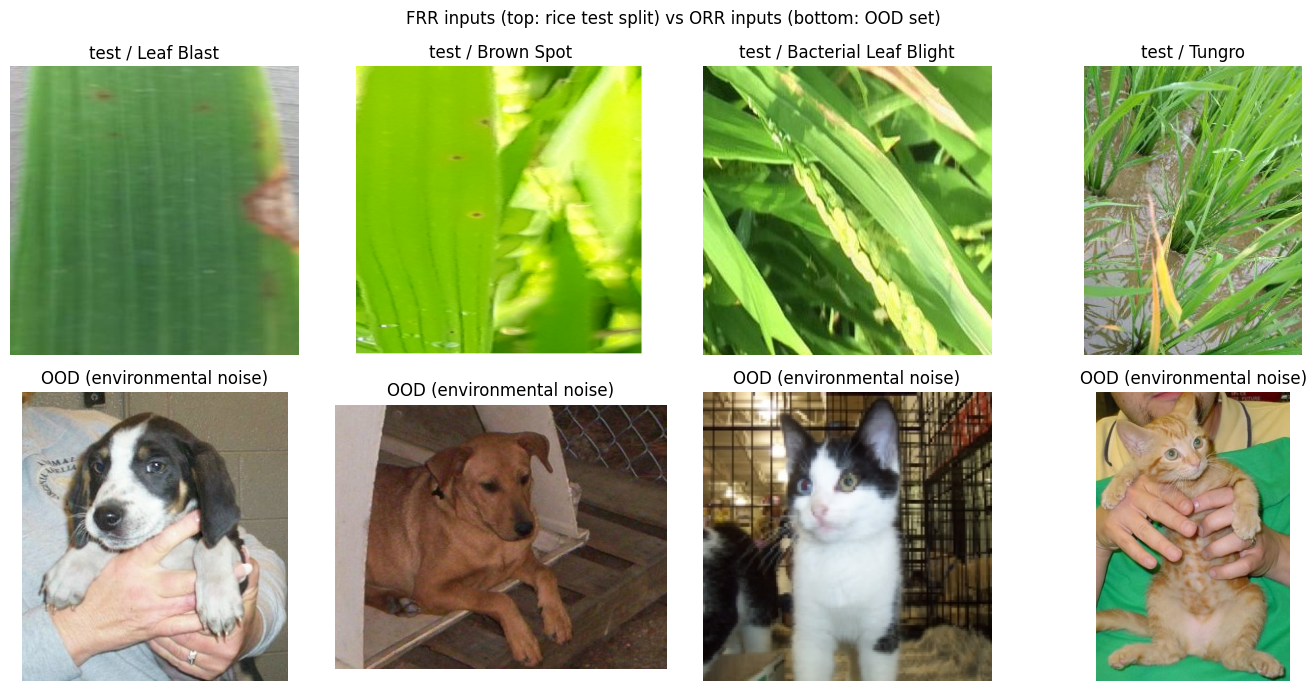

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from dataset import build_positive_index, DISEASES
import random

random.seed(0)

test_samples = build_positive_index(test_dir)
ood_paths = _list_images(ood_dir)

by_class = {}
for path, cls in test_samples:
    by_class.setdefault(cls, []).append(path)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, cls in enumerate(sorted(by_class)):
    path = by_class[cls][0]
    axes[0, i].imshow(Image.open(path).convert("RGB"))
    axes[0, i].set_title(f"test / {DISEASES[cls]}")
    axes[0, i].axis("off")
for i in range(4):
    axes[1, i].imshow(Image.open(ood_paths[i]).convert("RGB"))
    axes[1, i].set_title("OOD (environmental noise)")
    axes[1, i].axis("off")
fig.suptitle("FRR inputs (top: rice test split) vs ORR inputs (bottom: OOD set)")
fig.tight_layout()
plt.savefig("/content/fig_input_preview.png", dpi=110, bbox_inches="tight")
plt.show()

### 7. Stage I Bio-Grey Filter on one rice and one OOD image / Stage I（Bio-Grey フィルタ）の可視化

Stage I is model-independent HSV filtering: plant-pixel ratio = pixels with
H∈[12,65], S>60, V>40 (image downscaled if wider than 640), **pass if ratio ≥ 0.35**.
The overlay below visualizes exactly the author rule from `cascade_inference.py::bio_grey_pass`
(`cv2` BGR→HSV). Expected: the rice leaf passes (ratio ≥ 0.35), the OOD cat/dog image is rejected.
**出力:** 植物ピクセルマスクのオーバーレイと両画像の ratio・合否判定。

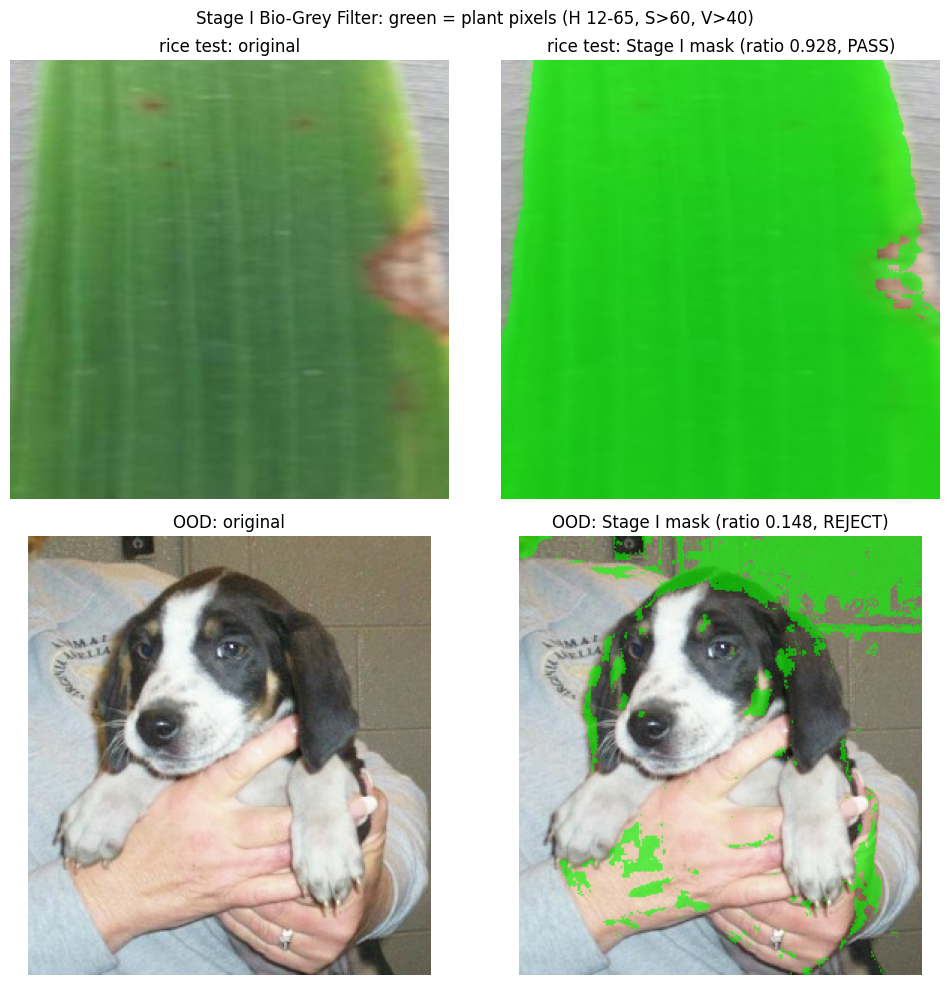

In [ ]:
import cv2

def stage1_mask(img_path):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    if w > 640:
        s = 640 / w
        img = cv2.resize(img, (0, 0), fx=s, fy=s)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = ((hsv[:, :, 0] >= 12) & (hsv[:, :, 0] <= 65) &
            (hsv[:, :, 1] > 60) & (hsv[:, :, 2] > 40))
    return img, mask

rice_path = by_class[0][0]      # one Leaf Blast test image
ood_path = ood_paths[0]         # first OOD image

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for row, (p, label) in enumerate([(rice_path, "rice test"), (ood_path, "OOD")]):
    img, mask = stage1_mask(p)
    ratio = mask.mean()
    overlay = img.copy()
    overlay[mask] = (0.4 * overlay[mask] + 0.6 * np.array([0, 255, 0])).astype(np.uint8)
    axes[row, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{label}: original")
    axes[row, 1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[row, 1].set_title(f"{label}: Stage I mask (ratio {ratio:.3f}, "
                           f"{'PASS' if ratio >= 0.35 else 'REJECT'})")
    for ax in axes[row]:
        ax.axis("off")
fig.suptitle("Stage I Bio-Grey Filter: green = plant pixels (H 12-65, S>60, V>40)")
fig.tight_layout()
plt.savefig("/content/fig_stage1_mask.png", dpi=110, bbox_inches="tight")
plt.show()

### 8. FRR on the 595-image test split / テスト分割での FRR 評価

Runs the authors' `evaluate_FRR` on the fixed test split, exactly as `code/run_frr.py`
does for the released checkpoint. Reference (repo `results/RESULTS.md`, single reference
split): **FRR 6.39% = 38/595, all rejected at Stage I**.
**出力:** FRR と Stage I / Stage II の内訳。

In [ ]:
import time
from cascade_inference import evaluate_FRR

t0 = time.time()
frr = evaluate_FRR(model, test_samples, DEVICE, num_workers=0)
frr_s = time.time() - t0
print("===== False Rejection Rate (positive test set) =====")
print(f"Positive test images        : {frr['n']}")
print(f"Falsely rejected by CIS     : {frr['false_rejected']}  (Stage I: {frr['stage1']}, Stage II: {frr['stage2']})")
print(f"FRR                         : {frr['FRR']*100:.2f}%   (paper repo RESULTS.md: 6.39% = 38/595, all Stage I)")
print(f"evaluation time: {frr_s:.0f} s on {DEVICE}")

===== False Rejection Rate (positive test set) =====
Positive test images        : 595
Falsely rejected by CIS     : 38  (Stage I: 38, Stage II: 0)
FRR                         : 6.39%   (paper repo RESULTS.md: 6.39% = 38/595, all Stage I)
evaluation time: 231 s on cpu


### 9. ORR on the 1,000 OOD images / OOD 画像での ORR 評価

Runs the authors' `evaluate_ORR` over all 1,000 environmental-noise images.
Reference (repo `results/RESULTS.md`, single reference split): **ORR 81.30% = 813/1000
(Stage I 763 + Stage II 50)**; Stage I alone is deterministic (model-independent) and
rejects 763/1000 = 76.3% in every run.
**出力:** ORR と Stage I / Stage II の内訳。

In [ ]:
from cascade_inference import evaluate_ORR

t0 = time.time()
orr = evaluate_ORR(model, ood_paths, DEVICE, num_workers=0)
orr_s = time.time() - t0
print("===== OOD Rejection Rate (sanity check vs paper) =====")
print(f"Negative samples            : {orr['n']}")
print(f"Rejected                    : {orr['rejected']}  (Stage I: {orr['stage1']}, Stage II: {orr['stage2']})")
print(f"ORR                         : {orr['ORR']*100:.2f}%   (paper repo RESULTS.md: 81.30% = 813/1000)")
print(f"Stage-I-only reference      : 763/1000 = 76.3% (deterministic, model-independent)")
print(f"evaluation time: {orr_s:.0f} s on {DEVICE}")

===== OOD Rejection Rate (sanity check vs paper) =====
Negative samples            : 1000
Rejected                    : 813  (Stage I: 763, Stage II: 50)
ORR                         : 81.30%   (paper repo RESULTS.md: 81.30% = 813/1000)
Stage-I-only reference      : 763/1000 = 76.3% (deterministic, model-independent)
evaluation time: 279 s on cpu


### 10. Observed vs reference values / 観測値と参考値の比較

Compares this run against the authors' recorded single-checkpoint results
(repo `results/RESULTS.md`, released checkpoint on the fixed reference split).
Small deviations in the Stage II count can stem from library-version differences in the
backbone forward pass; Stage I is purely image-based and must match exactly.
**出力:** 比較表と `/content/cis_results.csv` への保存。

In [ ]:
import pandas as pd

rows = [
    ("FRR", f"{frr['false_rejected']}/{frr['n']}", f"{frr['FRR']*100:.2f}%", "38/595", "6.39%"),
    ("  Stage I rejections", f"{frr['stage1']}", "", "38", "all Stage I"),
    ("  Stage II rejections", f"{frr['stage2']}", "", "0", ""),
    ("ORR", f"{orr['rejected']}/{orr['n']}", f"{orr['ORR']*100:.2f}%", "813/1000", "81.30%"),
    ("  Stage I rejections", f"{orr['stage1']}", "", "763", "76.3%"),
    ("  Stage II rejections", f"{orr['stage2']}", "", "50", ""),
]
df = pd.DataFrame(rows, columns=["metric", "observed (count)", "observed (%)", "reference (RESULTS.md)", "reference (%)"])
df.to_csv("/content/cis_results.csv", index=False)
print(df.to_string(index=False))

               metric observed (count) observed (%) reference (RESULTS.md) reference (%)
                  FRR           38/595        6.39%                 38/595         6.39%
   Stage I rejections               38                                  38   all Stage I
  Stage II rejections                0                                   0              
                  ORR         813/1000       81.30%               813/1000        81.30%
   Stage I rejections              763                                 763         76.3%
  Stage II rejections               50                                  50              


## Interpretation and limitations / 解釈と限界

- The evaluated **Stage I Bio-Grey Filter is deterministic and model-independent**;
  its counts (especially the 763/1000 OOD rejections) should match the paper exactly.
  Any difference there would indicate a preprocessing/environment discrepancy, not model variance.
- **Stage II depends on the model forward pass**, so its attributed count may shift slightly
  across torch/torchvision versions; the authors themselves load with `strict=False` and
  treat Stage II as the seed-varying component.
- This single-checkpoint run on the fixed reference split is the authors' own documented
  reproduction command (`code/run_frr.py`); it does **not** verify the 5-seed statistics
  (ORR 78.16 ± 0.57% under source-aware CV per the paper) nor the training pipeline.
- The paper's `run_frr.py` docstring mentions 818/1000 (81.80%) while the repo's
  `results/RESULTS.md` records 813/1000 (81.30%); the RESULTS.md table is used as reference here.
- License note: the GitHub repository has **no LICENSE file** (reuse terms unverified);
  the Figshare data archive is CC BY 4.0. Cite the PLOS ONE article when reusing.

**このデモは 1 つのチェックポイントによる固定分割評価であり、論文の多シード統計や学習の再現ではありません。**

## Validation record / 検証記録

Outputs in this notebook were produced by executing it top-to-bottom on fresh Google Colab
runtimes (CPU and T4) on 2026-11-14/15; the device and timings printed in the cells above are
from those runs. Sources: PLOS ONE e0362080; MTRNet commit `803ec0e`; Figshare 33065840 v1
(verified MD5). PhenoPaper public_id: `p-adaab1acba5e07841a8eeb4070c437f5`.

## References

1. Lyu, Bai, Yu, Liu. Knowledge-guided multi-task learning with cascade out-of-distribution
   rejection for rice leaf disease diagnosis. PLOS ONE 21(11): e0362080 (2026).
   https://doi.org/10.1371/journal.pone.0362080
2. MTRNet code: https://github.com/lvxiangfly/MTRNet (commit 803ec0ef19c340f52490f505838d27ae17889d47)
3. Data + checkpoint: https://doi.org/10.6084/m9.figshare.33065840 (CC BY 4.0)
4. Sethy, P. K. Rice leaf disease image samples. Mendeley Data (2020). https://doi.org/10.17632/fwcj7stb8r.1